# Рубежный контроль №2

**Студент:** Зеленцов Антон
**Группа:** ИУ5-61Б
**Вариант:** №9 — набор данных №9, Global Housing Market Analysis (2015–2024)
**Методы:** №1 — линейная/логистическая регрессия, №2 — случайный лес

**Тема:** методы построения моделей машинного обучения.

**Задание.** Для заданного набора данных построить модели классификации или регрессии
(в зависимости от конкретной задачи, рассматриваемой в наборе данных). Для построения
моделей использовать методы 1 и 2 по варианту группы. Оценить качество моделей на основе
подходящих метрик качества (не менее двух метрик). Ответить на вопросы: какие метрики
качества использованы и почему, какие выводы можно сделать о качестве построенных моделей.
Для построения моделей выполнить требуемую предобработку данных: заполнение пропусков,
кодирование категориальных признаков и т.д.

**Ссылка на задание:** https://github.com/ugapanyuk/courses_current/wiki/TMO_RK_2


In [1]:
# -*- coding: utf-8 -*-
"""
Рубежный контроль №2 по курсу «Технологии разведочного анализа и обработки данных».

Вариант №9: набор данных №9 — Global Housing Market Analysis (2015–2024).
Группа ИУ5-61Б: метод №1 — линейная/логистическая регрессия, метод №2 — случайный лес.

Задание: построить модели регрессии для заданного набора данных, выполнить необходимую
предобработку (заполнение пропусков, кодирование категориальных признаков), оценить
качество не менее чем двумя метриками и ответить на вопросы задания.

Скрипт соответствует ноутбуку РК_2.ipynb и запускается из папки проекта:
    python РК_2.py

Результаты: data/*.csv, графики в папке screenshots/.
"""


'\nРубежный контроль №2 по курсу «Технологии разведочного анализа и обработки данных».\n\nВариант №9: набор данных №9 — Global Housing Market Analysis (2015–2024).\nГруппа ИУ5-61Б: метод №1 — линейная/логистическая регрессия, метод №2 — случайный лес.\n\nЗадание: построить модели регрессии для заданного набора данных, выполнить необходимую\nпредобработку (заполнение пропусков, кодирование категориальных признаков), оценить\nкачество не менее чем двумя метриками и ответить на вопросы задания.\n\nСкрипт соответствует ноутбуку РК_2.ipynb и запускается из папки проекта:\n    python РК_2.py\n\nРезультаты: data/*.csv, графики в папке screenshots/.\n'

# Рубежный контроль №2

**Тема:** методы построения моделей машинного обучения.

**Вариант №9:** набор данных №9 — Global Housing Market Analysis (2015–2024).

**Группа ИУ5-61Б:** метод №1 — линейная/логистическая регрессия, метод №2 — случайный лес.

**Задача:** регрессия — предсказание индекса цен на жильё (`House Price Index`)
по экономическим и демографическим показателям страны за год.


In [2]:
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib

%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.inspection import permutation_importance

try:  # в ноутбуке — красивые таблицы, в скрипте — обычный вывод
    from IPython.display import display
except ImportError:  # pragma: no cover
    display = print

# Кириллица в подписях графиков
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="DejaVu Sans")

RANDOM_STATE = 42
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
FIG_DIR = BASE_DIR / "screenshots"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)


def save_fig(fig, name):
    """Сохраняет рисунок в папку screenshots — эти же файлы вставлены в отчет."""
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    

print("pandas:", pd.__version__, "| numpy:", np.__version__)
print("scikit-learn:", __import__("sklearn").__version__, "| seaborn:", sns.__version__)


pandas: 2.2.3 | numpy: 2.1.1
scikit-learn: 1.9.0 | seaborn: 0.13.2


## 1. Загрузка и первичный обзор набора данных


In [3]:
df = pd.read_csv(DATA_DIR / "global_housing_market_extended.csv")

TARGET = "House Price Index"
CAT_FEATURES = ["Country"]
NUM_FEATURES = [c for c in df.columns if c not in CAT_FEATURES + [TARGET]]
FEATURES = NUM_FEATURES + CAT_FEATURES

print("Размер набора:", df.shape)
print("\nТипы признаков:")
print(df.dtypes.to_string())
print("\nПропуски по столбцам:")
print(df.isna().sum().to_string())
print("\nПолных дубликатов строк:", int(df.duplicated().sum()))
print("\nЧисло стран:", df["Country"].nunique(), "| годы:", df["Year"].min(), "—", df["Year"].max())
print("\nЧисло наблюдений по странам:")
print(df["Country"].value_counts().to_string())

display(df.head(10))
display(df[NUM_FEATURES + [TARGET]].describe().T.round(3))


Размер набора: (200, 11)

Типы признаков:
Country                   object
Year                       int64
House Price Index        float64
Rent Index               float64
Affordability Ratio      float64
Mortgage Rate (%)        float64
Inflation Rate (%)       float64
GDP Growth (%)           float64
Population Growth (%)    float64
Urbanization Rate (%)    float64
Construction Index       float64

Пропуски по столбцам:
Country                  0
Year                     0
House Price Index        0
Rent Index               0
Affordability Ratio      0
Mortgage Rate (%)        0
Inflation Rate (%)       0
GDP Growth (%)           0
Population Growth (%)    0
Urbanization Rate (%)    0
Construction Index       0

Полных дубликатов строк: 0

Число стран: 20 | годы: 2015 — 2024

Число наблюдений по странам:
Country
USA             10
Canada          10
Switzerland     10
Sweden          10
Netherlands     10
Russia          10
South Africa    10
Mexico          10
South Korea     10
B

,Country,Year,House Price Index,Rent Index,Affordability Ratio,Mortgage Rate (%),Inflation Rate (%),GDP Growth (%),Population Growth (%),Urbanization Rate (%),Construction Index
0,USA,2015,117.454012,116.550001,9.587945,4.493292,1.514121,-0.752044,-0.796707,85.985284,118.089201
1,USA,2016,150.807258,51.440915,11.729189,5.662213,1.880204,-0.545400,-0.358084,69.127267,111.980515
2,USA,2017,123.194502,70.386040,8.506676,2.197469,2.398940,0.930895,0.596245,83.555279,85.973903
3,USA,2018,131.423444,91.469020,3.418054,4.537724,1.608407,-1.479587,2.321099,88.968961,134.671788
4,USA,2019,110.461377,56.837048,9.158097,3.700762,1.293249,1.961415,-0.879640,87.279612,90.702399
5,USA,2020,146.252228,71.819775,7.680612,4.233551,1.701554,5.756677,1.712965,88.184968,141.586188
6,USA,2021,139.789998,114.531196,3.796433,2.479914,0.793977,0.602643,0.360371,68.140471,136.299001
7,USA,2022,115.675333,69.665416,7.884265,2.204621,5.714280,-1.403595,2.454104,83.167343,85.897255
8,USA,2023,80.552212,107.082300,9.361716,5.145036,5.513257,-1.407643,0.254630,63.476072,139.048274
9,USA,2024,142.329813,73.162862,3.572025,3.054912,2.613692,3.836849,1.231451,86.616382,107.777194


,count,mean,std,min,25%,50%,75%,max
Year,200.0,2019.500,2.879,2015.000,2017.000,2019.500,2022.000,2024.000
Rent Index,200.0,83.048,21.440,50.354,60.467,83.722,100.605,119.855
Affordability Ratio,200.0,7.238,2.576,3.042,5.034,7.376,9.276,11.880
Mortgage Rate (%),200.0,4.151,1.380,1.538,3.045,4.330,5.218,6.486
Inflation Rate (%),200.0,3.650,1.882,0.532,1.939,3.665,5.262,6.912
GDP Growth (%),200.0,2.134,2.413,-1.922,-0.096,2.308,4.273,5.959
Population Growth (%),200.0,0.723,1.036,-0.961,-0.183,0.722,1.621,2.498
Urbanization Rate (%),200.0,74.770,8.734,60.173,66.924,75.100,82.677,89.789
Construction Index,200.0,111.204,24.309,70.969,90.182,110.594,133.780,149.736
House Price Index,200.0,130.381,28.752,80.552,104.143,129.194,157.127,179.972


Набор содержит 200 наблюдений: 20 стран за 10 лет (2015–2024), по 10 наблюдений
на страну. Пропусков и дубликатов нет. Категориальный признак один — `Country`
(20 уровней), остальные 9 признаков количественные. Целевая переменная —
`House Price Index` (индекс цен на жильё, безразмерная величина, больше нуля).


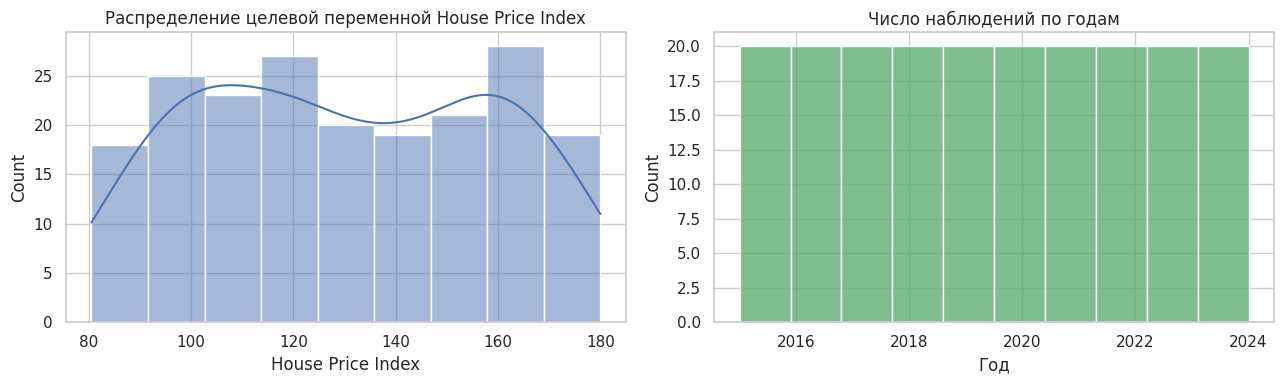

Асимметрия целевой переменной: 0.033
Эксцесс целевой переменной: -1.218


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[TARGET], kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Распределение целевой переменной House Price Index")
axes[0].set_xlabel("House Price Index")

sns.histplot(df["Year"], bins=10, ax=axes[1], color="#55A868")
axes[1].set_title("Число наблюдений по годам")
axes[1].set_xlabel("Год")
plt.tight_layout()
save_fig(fig, "fig01_target_dist.png")
plt.show()

print("Асимметрия целевой переменной:", round(df[TARGET].skew(), 3))
print("Эксцесс целевой переменной:", round(df[TARGET].kurt(), 3))


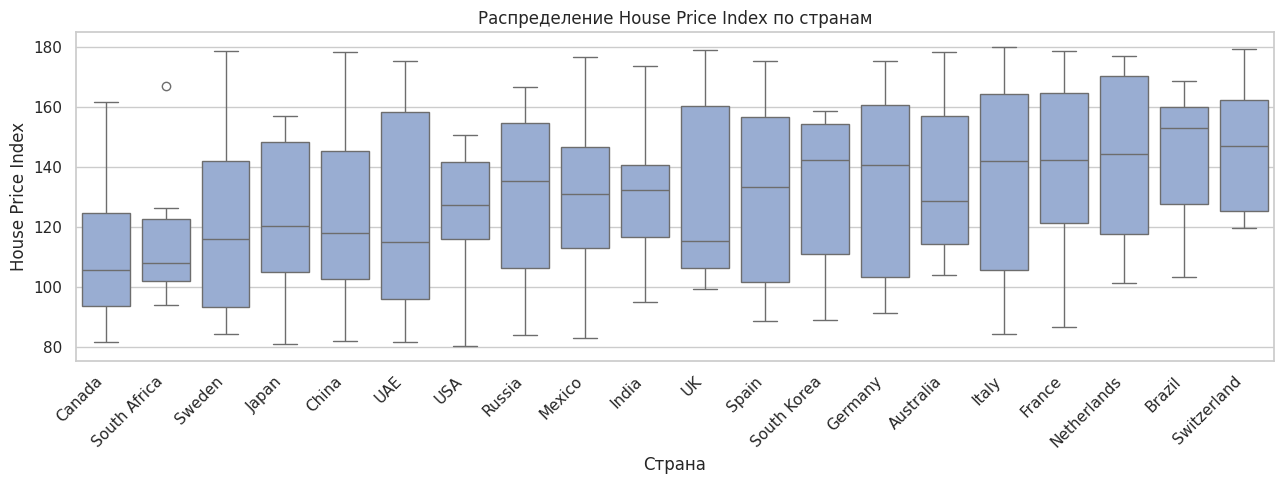

,mean,std,min,max
Country,,,,
Canada,112.1,25.4,81.7,161.8
South Africa,114.5,21.4,94.2,167.1
Sweden,120.2,30.6,84.3,178.8
Japan,122.3,28.5,81.1,157.1
China,123.8,32.4,82.0,178.5
UAE,125.2,34.4,81.9,175.5
USA,125.8,21.1,80.6,150.8
Russia,130.3,31.0,84.2,166.7
Mexico,130.4,27.6,83.1,176.9


Среднеквадратичное отклонение средних по странам: 9.06
Среднее внутристрановое стандартное отклонение: 28.48


In [5]:
order = df.groupby("Country")[TARGET].mean().sort_values().index
fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=df, x="Country", y=TARGET, order=order, ax=ax, color="#8FAADC")
ax.set_title("Распределение House Price Index по странам")
ax.set_xlabel("Страна")
ax.set_ylabel("House Price Index")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
save_fig(fig, "fig02_hpi_by_country.png")
plt.show()

country_stats = df.groupby("Country")[TARGET].agg(["mean", "std", "min", "max"]).round(1)
country_stats = country_stats.sort_values("mean")
display(country_stats)
print("Среднеквадратичное отклонение средних по странам:", round(country_stats["mean"].std(), 2))
print("Среднее внутристрановое стандартное отклонение:", round(country_stats["std"].mean(), 2))


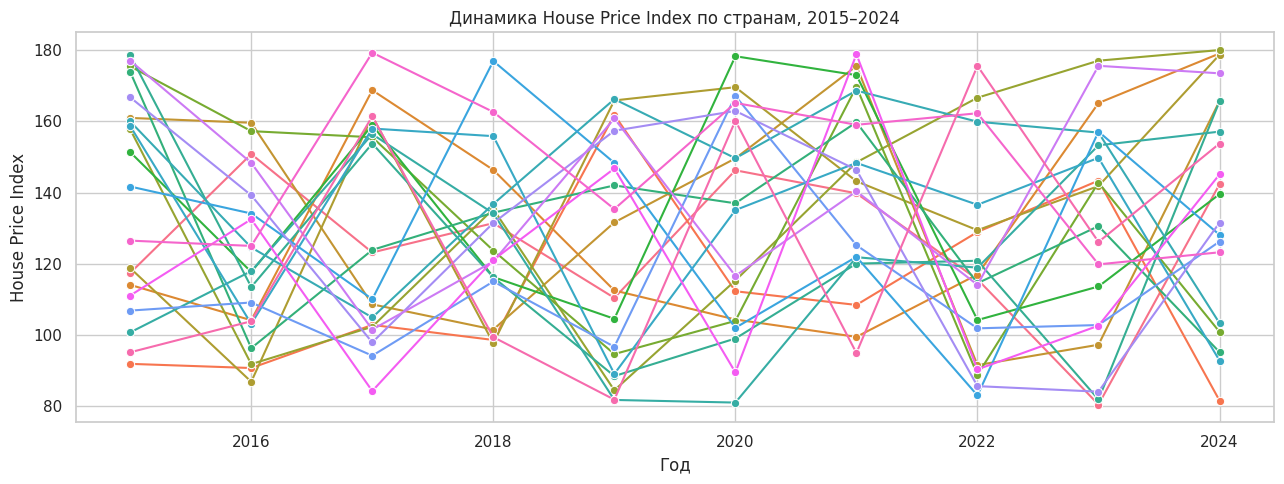

,mean,std
Year,,
2015,139.23,30.06
2016,120.35,22.63
2017,130.37,30.51
2018,127.79,21.50
2019,123.06,31.54
2020,132.26,30.17
2021,142.14,25.47
2022,120.31,28.03
2023,130.12,30.93


Разброс среднегодовых значений: 7.77
Средний внутригодовой разброс: 28.22


In [6]:
fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=df, x="Year", y=TARGET, hue="Country", marker="o", ax=ax, legend=False)
ax.set_title("Динамика House Price Index по странам, 2015–2024")
ax.set_xlabel("Год")
ax.set_ylabel("House Price Index")
plt.tight_layout()
save_fig(fig, "fig03_hpi_by_year.png")
plt.show()

by_year = df.groupby("Year")[TARGET].agg(["mean", "std"]).round(2)
display(by_year)
print("Разброс среднегодовых значений:", round(by_year["mean"].std(), 2))
print("Средний внутригодовой разброс:", round(by_year["std"].mean(), 2))


Уже на этапе разведочного анализа видно важное свойство набора: разброс целевой
переменной внутри страны и внутри года (порядка 25–30 пунктов) многократно
превышает разброс средних значений между странами (около 9 пунктов) и между
годами. Иными словами, ни страна, ни год не объясняют основную часть дисперсии
индекса цен.


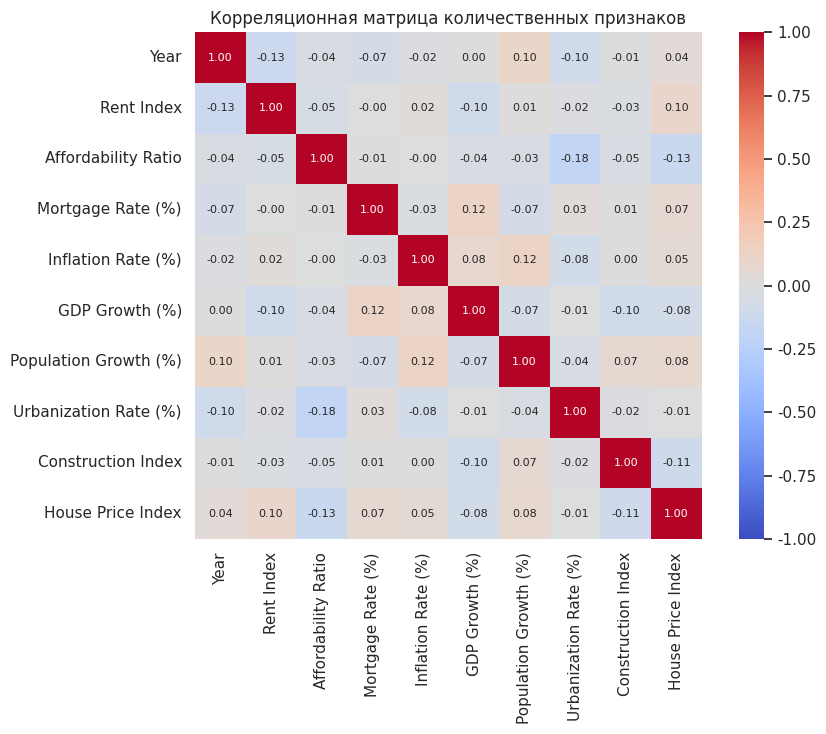

,House Price Index
Rent Index,0.098
Population Growth (%),0.077
Mortgage Rate (%),0.070
Inflation Rate (%),0.050
Year,0.037
Urbanization Rate (%),-0.006
GDP Growth (%),-0.081
Construction Index,-0.109
Affordability Ratio,-0.133


Максимальный по модулю коэффициент корреляции с целевой переменной: 0.133


In [7]:
corr = df[NUM_FEATURES + [TARGET]].corr().round(3)

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, ax=ax, annot_kws={"size": 8})
ax.set_title("Корреляционная матрица количественных признаков")
plt.tight_layout()
save_fig(fig, "fig04_corr.png")
plt.show()

display(corr[[TARGET]].drop(index=TARGET).sort_values(TARGET, ascending=False))
corr.to_csv(DATA_DIR / "correlation.csv")
print("Максимальный по модулю коэффициент корреляции с целевой переменной:",
      round(corr[TARGET].drop(TARGET).abs().max(), 3))


## 2. Предобработка данных

Требуемая по заданию предобработка включает:

1. **Обработку пропусков.** В исходном наборе пропусков нет, поэтому пайплайн
   дополнен импьютерами (`SimpleImputer`), которые включаются автоматически,
   если пропуски появятся. Чтобы убедиться в работоспособности этой части,
   ниже выполняется демонстрационный эксперимент: в данные вносится 5 %
   пропусков, они заполняются, и результат сравнивается с исходным набором.
2. **Кодирование категориальных признаков.** Признак `Country` кодируется
   методом one-hot (OHE, `drop="first"` — чтобы не возникало линейной
   зависимости между столбцами).
3. **Масштабирование количественных признаков.** `StandardScaler` — обязателен
   для линейной модели (коэффициенты становятся сравнимыми, улучшается
   обусловленность матрицы), для случайного леса не влияет на результат.

Все шаги объединены в `Pipeline`, поэтому параметры предобработки вычисляются
только на обучающей части выборки — это исключает утечку данных (data leakage).


In [8]:
# ---------- Демонстрация обработки пропусков ----------
rng = np.random.default_rng(RANDOM_STATE)
df_miss = df.copy()

miss_cols = ["Rent Index", "Mortgage Rate (%)", "GDP Growth (%)", "Construction Index"]
cat_idx = rng.choice(df.index, size=int(0.05 * len(df)), replace=False)

for col in miss_cols:
    rows = rng.choice(df.index.difference(cat_idx), size=int(0.05 * len(df)), replace=False)
    df_miss.loc[rows, col] = np.nan
df_miss.loc[cat_idx, "Country"] = np.nan

print("Внесено пропусков (демонстрационный набор):")
print(df_miss.isna().sum()[df_miss.isna().sum() > 0].to_string())
df_miss.to_csv(DATA_DIR / "housing_missing.csv", index=False)

# Заполнение: медиана для количественных, мода для категориального
df_prep = df_miss.copy()
for col in NUM_FEATURES:
    df_prep[col] = df_prep[col].fillna(df_miss[col].median())
df_prep["Country"] = df_prep["Country"].fillna(df_miss["Country"].mode()[0])

print("\nПропусков после заполнения:", int(df_prep.isna().sum().sum()))

recovery = pd.DataFrame({
    "Признак": miss_cols,
    "Пропусков": [int(df_miss[c].isna().sum()) for c in miss_cols],
    "MAE после заполнения": [
        round(mean_absolute_error(df.loc[df_miss[c].isna(), c], df_prep.loc[df_miss[c].isna(), c]), 3)
        for c in miss_cols
    ],
    "Std исходного признака": [round(df[c].std(), 3) for c in miss_cols],
})
recovery["Отношение MAE / Std"] = (recovery["MAE после заполнения"] / recovery["Std исходного признака"]).round(2)
display(recovery)
recovery.to_csv(DATA_DIR / "missing_recovery.csv", index=False)

country_recovery = (df.loc[cat_idx, "Country"] == df_prep.loc[cat_idx, "Country"]).mean()
print("Верно восстановлено категорий Country:", f"{country_recovery:.1%}")
print("Доля верно восстановленных категорий при случайном угадывании: 5.0 %")

df_prep.to_csv(DATA_DIR / "housing_prepared.csv", index=False)
print("\nПодготовленный набор сохранён: data/housing_prepared.csv")


Внесено пропусков (демонстрационный набор):
Country               10
Rent Index            10
Mortgage Rate (%)     10
GDP Growth (%)        10
Construction Index    10

Пропусков после заполнения: 0


,Признак,Пропусков,MAE после заполнения,Std исходного признака,Отношение MAE / Std
0,Rent Index,10,21.185,21.440,0.99
1,Mortgage Rate (%),10,1.465,1.380,1.06
2,GDP Growth (%),10,2.195,2.413,0.91
3,Construction Index,10,26.379,24.309,1.09


Верно восстановлено категорий Country: 0.0%
Доля верно восстановленных категорий при случайном угадывании: 5.0 %

Подготовленный набор сохранён: data/housing_prepared.csv


Результат показателен: ошибка заполнения медианой практически совпадает
со стандартным отклонением самого признака (отношение MAE / Std близко
к единице). Это значит, что медиана не улучшает прогноз по сравнению
с «типичным значением признака» — иными словами, соседние признаки
не содержат информации о пропущенном значении. Для категориального
признака мода восстанавливает 0 % значений при уровне случайного
угадывания 1/20 = 5 %, что подтверждает тот же вывод: страну по остальным
показателям определить нельзя.

Этот результат — первое указание на ключевое свойство набора данных,
которое полностью проявится при построении моделей: признаки в наборе
практически независимы друг от друга и от целевой переменной.


In [9]:
# ---------- Пайплайн предобработки ----------
def make_preprocessor():
    """Единый препроцессор: импьютеры + масштабирование + one-hot для Country."""
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric, NUM_FEATURES),
        ("cat", categorical, CAT_FEATURES),
    ])


def make_pipeline(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])


X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Обучающая выборка:", X_train.shape[0], "| тестовая выборка:", X_test.shape[0])

CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}


def evaluate(model, name):
    """Метрики на тестовой выборке и по кросс-валидации."""
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    row = {
        "Модель": name,
        "R² (тест)": r2_score(y_test, pred),
        "MAE (тест)": mean_absolute_error(y_test, pred),
        "RMSE (тест)": np.sqrt(mean_squared_error(y_test, pred)),
        "MAPE, % (тест)": mean_absolute_percentage_error(y_test, pred) * 100,
    }

    cv_res = cross_validate(model, X, y, cv=CV, scoring=SCORING, n_jobs=-1)
    row["R² (CV)"] = cv_res["test_r2"].mean()
    row["R² std (CV)"] = cv_res["test_r2"].std()
    row["MAE (CV)"] = -cv_res["test_mae"].mean()
    row["RMSE (CV)"] = -cv_res["test_rmse"].mean()

    row["_pred"] = pred
    return row


Обучающая выборка: 160 | тестовая выборка: 40


## 3. Базовые решения (baseline)

Прежде чем сравнивать модели между собой, нужно понять, какой результат даёт
тривиальный прогноз. Рассматриваются два baseline:

* **константа** — среднее (или медиана) целевой переменной по обучающей выборке;
* **среднее по стране** — для каждого объекта прогноз равен среднему индексу
  цен его страны, вычисленному по обучающей части выборки. Этот baseline
  показывает, сколько информации несёт сам факт принадлежности к стране.

Если модель не превосходит baseline, значит она не извлекла из признаков
никакой полезной информации.


In [10]:
def country_mean_baseline(X_tr, y_tr, X_te):
    """Прогноз = средний индекс цен страны, вычисленный по обучающей выборке."""
    means = y_tr.groupby(X_tr["Country"]).mean()
    fallback = y_tr.mean()
    return X_te["Country"].map(means).fillna(fallback)


def cv_country_baseline(X, y, cv):
    """Кросс-валидация baseline «среднее по стране»."""
    preds = pd.Series(index=y.index, dtype=float)
    for tr_idx, te_idx in cv.split(X):
        preds.iloc[te_idx] = country_mean_baseline(X.iloc[tr_idx], y.iloc[tr_idx], X.iloc[te_idx]).values
    return preds


results = []
results.append(evaluate(make_pipeline(DummyRegressor(strategy="mean")), "Baseline (среднее)"))
results.append(evaluate(make_pipeline(DummyRegressor(strategy="median")), "Baseline (медиана)"))

# Baseline «среднее по стране»: считаем вручную, так как это не стандартный оценщик
base_pred_test = country_mean_baseline(X_train, y_train, X_test)
base_pred_cv = cv_country_baseline(X, y, CV)
results.append({
    "Модель": "Baseline (среднее по стране)",
    "R² (тест)": r2_score(y_test, base_pred_test),
    "MAE (тест)": mean_absolute_error(y_test, base_pred_test),
    "RMSE (тест)": np.sqrt(mean_squared_error(y_test, base_pred_test)),
    "MAPE, % (тест)": mean_absolute_percentage_error(y_test, base_pred_test) * 100,
    "R² (CV)": r2_score(y, base_pred_cv),
    "R² std (CV)": np.nan,
    "MAE (CV)": mean_absolute_error(y, base_pred_cv),
    "RMSE (CV)": np.sqrt(mean_squared_error(y, base_pred_cv)),
    "_pred": base_pred_test,
})

base_table = pd.DataFrame(results)[["Модель", "R² (тест)", "MAE (тест)", "RMSE (тест)", "MAPE, % (тест)"]]
display(base_table.round(3))
print("Разброс средних по странам:", round(y.groupby(X['Country']).mean().std(), 2),
      "| общий разброс целевой переменной:", round(y.std(), 2))


,Модель,R² (тест),MAE (тест),RMSE (тест),"MAPE, % (тест)"
0,Baseline (среднее),-0.005,27.551,30.434,23.250
1,Baseline (медиана),-0.002,27.510,30.387,23.076
2,Baseline (среднее по стране),-0.038,26.788,30.932,22.913


Разброс средних по странам: 9.06 | общий разброс целевой переменной: 28.75


## 4. Метод №1 — линейная регрессия

Линейная регрессия моделирует целевую переменную как линейную комбинацию
признаков. После one-hot кодирования страны и стандартизации количественных
признаков коэффициенты показывают, на сколько пунктов индекса изменяется
прогноз при изменении признака на одно стандартное отклонение (для
количественных) или при переходе к соответствующей стране.

Дополнительно рассматривается **гребневая регрессия (Ridge)** — линейная
модель с L2-регуляризацией. После one-hot кодирования страны признаков
становится 28 при 160 объектах обучающей выборки, поэтому обычная линейная
регрессия склонна к переобучению, а Ridge стабилизирует коэффициенты;
параметр регуляризации подбирается по сетке с кросс-валидацией.


In [11]:
results.append(evaluate(make_pipeline(LinearRegression()), "Линейная регрессия"))

ridge = make_pipeline(Ridge())
ridge_grid = {"model__alpha": np.logspace(-2, 3, 30)}
ridge_search = GridSearchCV(ridge, ridge_grid, cv=CV, scoring="r2", n_jobs=-1)
ridge_search.fit(X_train, y_train)
print("Ridge: лучшее значение alpha =", round(ridge_search.best_params_["model__alpha"], 3))
print("Ridge: R² на кросс-валидации (обучающая часть) =", round(ridge_search.best_score_, 4))

results.append(evaluate(ridge_search.best_estimator_, "Гребневая регрессия (Ridge)"))


Ridge: лучшее значение alpha = 303.92
Ridge: R² на кросс-валидации (обучающая часть) = -0.0763


,Коэффициент
Country_Netherlands,20.326
Country_Switzerland,19.720
Country_Canada,-17.961
Country_Russia,14.439
Country_South Korea,13.477
Country_Italy,12.925
Country_Mexico,12.607
Country_Brazil,12.133
Country_Spain,9.484
Country_South Africa,-9.103


Свободный член: 125.028


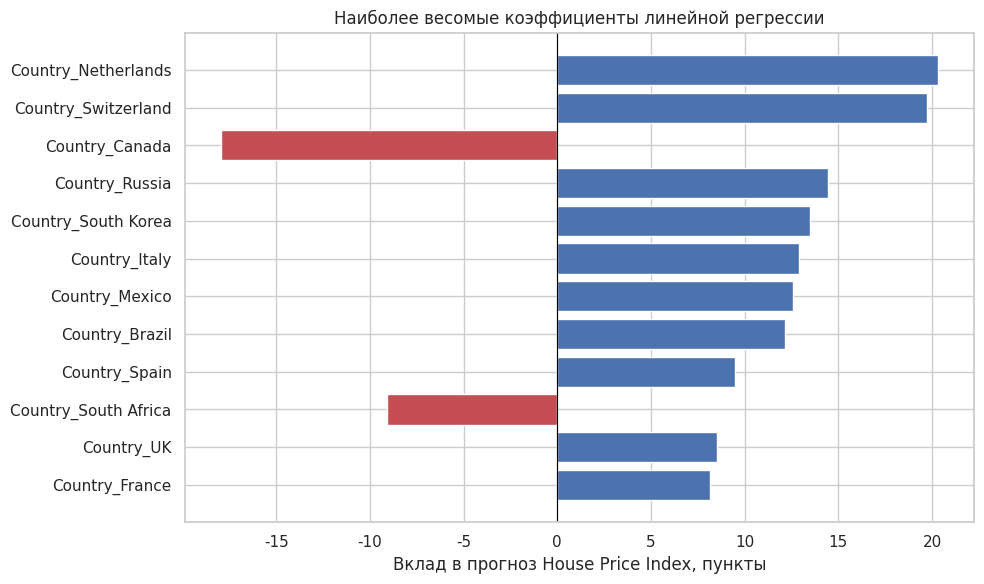

In [12]:
# Коэффициенты линейной модели (после стандартизации признаков)
lin = make_pipeline(LinearRegression()).fit(X_train, y_train)
feature_names = (
    NUM_FEATURES
    + list(lin.named_steps["prep"].named_transformers_["cat"]
           .named_steps["encoder"].get_feature_names_out(CAT_FEATURES))
)
coefs = pd.Series(lin.named_steps["model"].coef_, index=feature_names).sort_values(key=abs, ascending=False)

display(coefs.to_frame("Коэффициент").round(3).head(12))
coefs.to_frame("Коэффициент").round(3).to_csv(DATA_DIR / "linear_coefficients.csv")
print("Свободный член:", round(lin.named_steps["model"].intercept_, 3))

fig, ax = plt.subplots(figsize=(10, 6))
top = coefs.head(12).iloc[::-1]
colors = ["#C44E52" if v < 0 else "#4C72B0" for v in top]
ax.barh(top.index, top.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Наиболее весомые коэффициенты линейной регрессии")
ax.set_xlabel("Вклад в прогноз House Price Index, пункты")
plt.tight_layout()
save_fig(fig, "fig05_coef.png")
plt.show()


## 5. Метод №2 — случайный лес

Случайный лес — ансамбль решающих деревьев, каждое из которых строится
на bootstrap-подвыборке объектов и случайном подмножестве признаков в каждом
узле. Прогноз получается усреднением по деревьям. Метод не требует
масштабирования признаков и способен улавливать нелинейные зависимости
и взаимодействия, поэтому он служит естественной «проверкой» линейной модели:
если зависимость нелинейна, лес покажет заметно лучшее качество.

Гиперпараметры подбираются по сетке с кросс-валидацией: число деревьев,
максимальная глубина, минимальный размер листа, доля признаков в узле.


In [13]:
rf = make_pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
rf_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 1.0],
}
rf_search = GridSearchCV(rf, rf_grid, cv=CV, scoring="r2", n_jobs=-1)
rf_search.fit(X_train, y_train)

print("Случайный лес: лучшие гиперпараметры")
for key, value in rf_search.best_params_.items():
    print("   ", key.replace("model__", ""), "=", value)
print("R² на кросс-валидации (обучающая часть) =", round(rf_search.best_score_, 4))

results.append(evaluate(rf_search.best_estimator_, "Случайный лес"))


Случайный лес: лучшие гиперпараметры
    max_depth = 5
    max_features = sqrt
    min_samples_leaf = 2
    n_estimators = 200
R² на кросс-валидации (обучающая часть) = -0.0929


## 6. Сравнение моделей

Используются четыре метрики, каждая из которых отвечает на свой вопрос:

* **R² (коэффициент детерминации)** — какая доля дисперсии целевой переменной
  объяснена моделью. Основная метрика: она безразмерна, не зависит от масштаба
  и напрямую сопоставима с baseline (у константного прогноза R² ≤ 0).
* **MAE (средняя абсолютная ошибка)** — средняя ошибка прогноза в пунктах
  индекса. Устойчива к выбросам и интерпретируется в единицах измерения.
* **RMSE (корень из средней квадратичной ошибки)** — та же размерность,
  но сильнее штрафует крупные промахи; полезен для оценки «хвостов» ошибок.
* **MAPE (средняя абсолютная процентная ошибка)** — относительная ошибка,
  удобна для содержательной интерпретации («модель ошибается на N %»).

MAE и RMSE дополняют друг друга: расхождение между ними указывает
на наличие отдельных крупных ошибок. R² выбран как основная метрика,
потому что задача регрессионная, а целевая переменная имеет естественный
масштаб; MAPE добавлена как относительная характеристика точности.


In [14]:
metrics = pd.DataFrame(results)

show_cols = ["Модель", "R² (тест)", "MAE (тест)", "RMSE (тест)", "MAPE, % (тест)",
             "R² (CV)", "R² std (CV)", "MAE (CV)", "RMSE (CV)"]
final_table = metrics[show_cols].set_index("Модель").round(3)
display(final_table)

metrics.drop(columns=["_pred"]).to_csv(DATA_DIR / "model_metrics.csv", index=False)

# Описательные статистики по странам и годам — для отчёта
country_stats.to_csv(DATA_DIR / "country_stats.csv")
by_year.to_csv(DATA_DIR / "year_stats.csv")


,R² (тест),MAE (тест),RMSE (тест),"MAPE, % (тест)",R² (CV),R² std (CV),MAE (CV),RMSE (CV)
Модель,,,,,,,,
Baseline (среднее),-0.005,27.551,30.434,23.250,-0.008,0.011,25.117,28.689
Baseline (медиана),-0.002,27.510,30.387,23.076,-0.023,0.041,25.346,28.892
Baseline (среднее по стране),-0.038,26.788,30.932,22.913,-0.124,NaN,26.068,30.411
Линейная регрессия,-0.030,26.387,30.806,22.663,-0.207,0.163,26.643,31.297
Гребневая регрессия (Ridge),-0.005,27.361,30.433,23.132,-0.009,0.035,25.182,28.705
Случайный лес,-0.006,26.843,30.443,22.711,-0.048,0.073,25.392,29.232


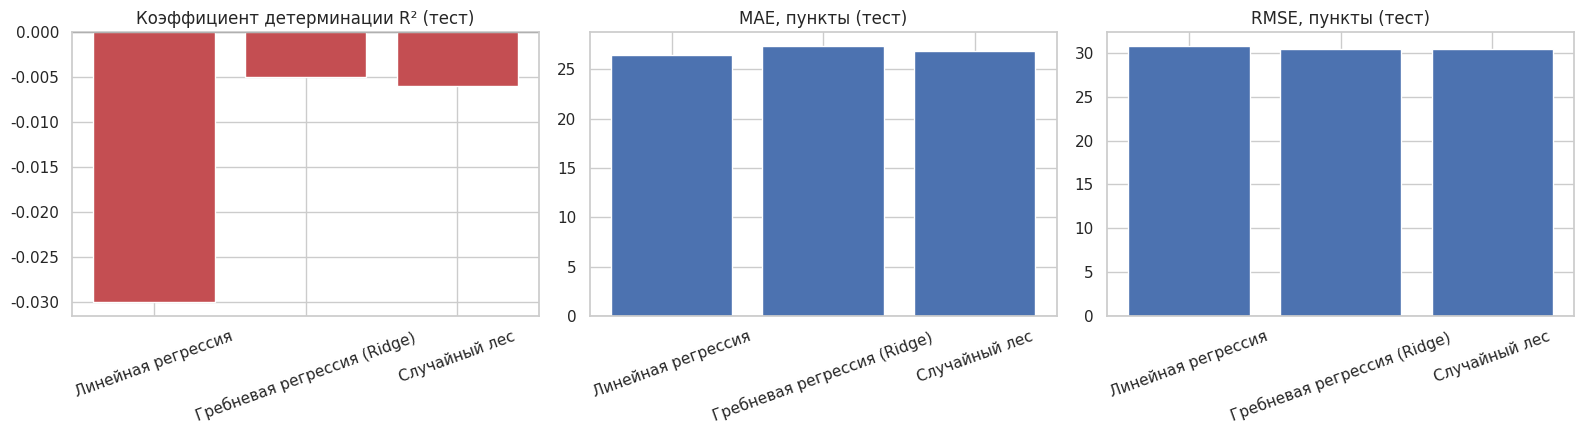

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_df = final_table.drop(index=[i for i in final_table.index if i.startswith("Baseline")])

for ax, col, title in zip(
    axes,
    ["R² (тест)", "MAE (тест)", "RMSE (тест)"],
    ["Коэффициент детерминации R² (тест)", "MAE, пункты (тест)", "RMSE, пункты (тест)"],
):
    colors = ["#4C72B0" if v >= 0 else "#C44E52" for v in plot_df[col]]
    ax.bar(plot_df.index, plot_df[col], color=colors)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)
    ax.axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
save_fig(fig, "fig06_metrics_compare.png")
plt.show()


## 7. Анализ качества: прогнозы, остатки, важность признаков


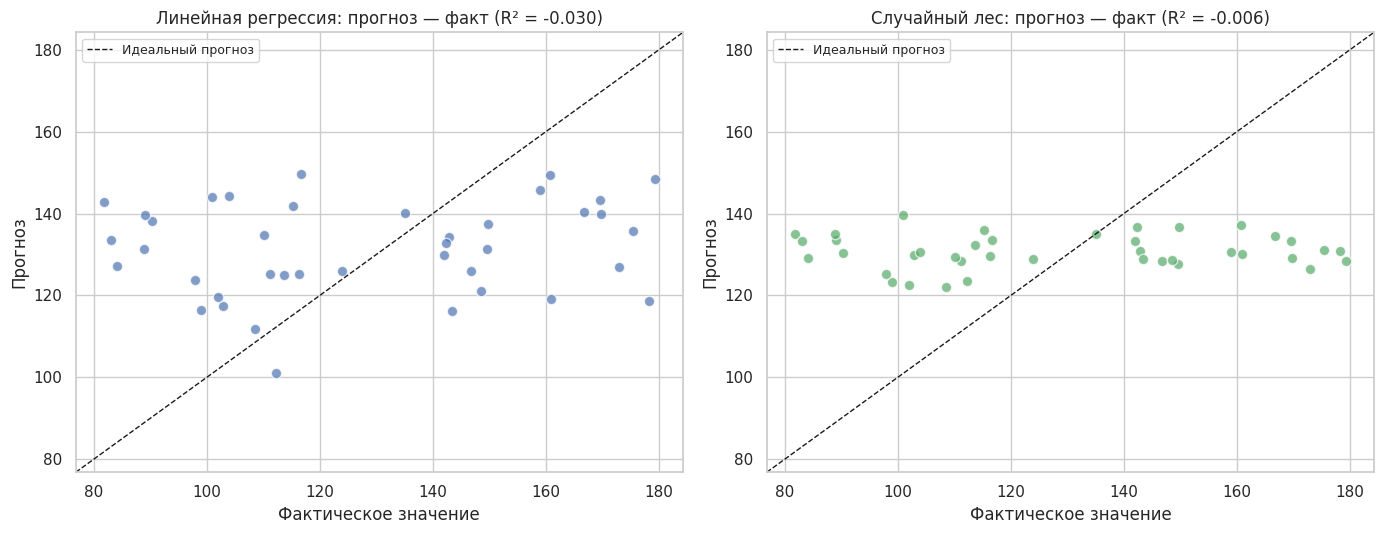

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, name, color in zip(axes, ["Линейная регрессия", "Случайный лес"], ["#4C72B0", "#55A868"]):
    row = next(r for r in results if r["Модель"] == name)
    pred = row["_pred"]
    ax.scatter(y_test, pred, alpha=0.7, color=color, edgecolor="white", s=55)
    lims = [min(y_test.min(), pred.min()) - 5, max(y_test.max(), pred.max()) + 5]
    ax.plot(lims, lims, "k--", linewidth=1, label="Идеальный прогноз")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Фактическое значение")
    ax.set_ylabel("Прогноз")
    ax.set_title(f"{name}: прогноз — факт (R² = {row['R² (тест)']:.3f})")
    ax.legend(loc="upper left", fontsize=9)

plt.tight_layout()
save_fig(fig, "fig07_pred_vs_actual.png")
plt.show()


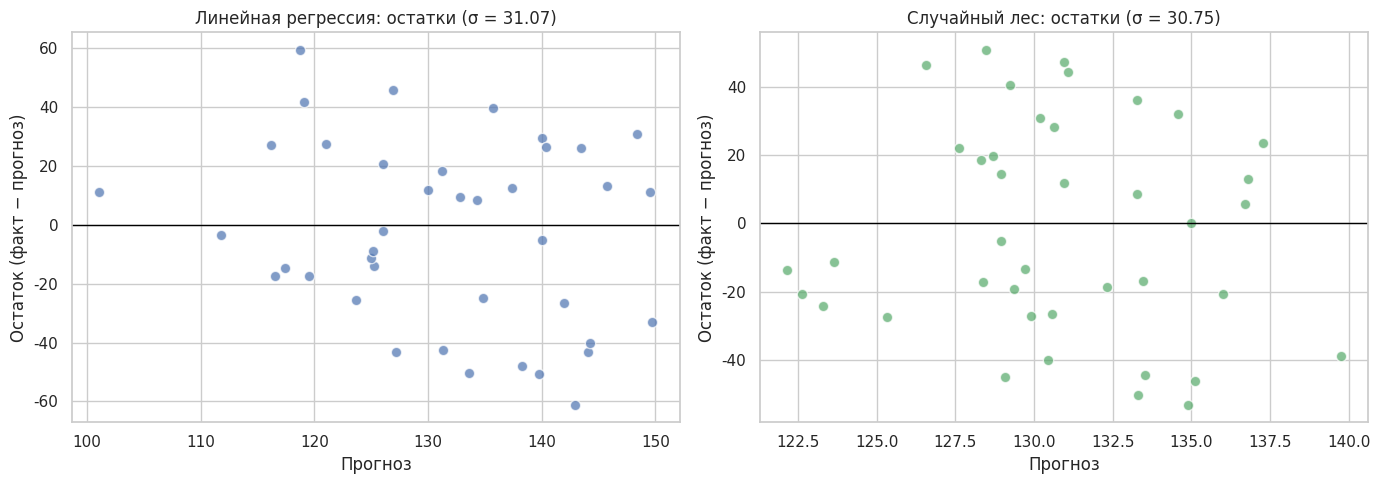

Стандартное отклонение целевой переменной на тесте: 30.741


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name, color in zip(axes, ["Линейная регрессия", "Случайный лес"], ["#4C72B0", "#55A868"]):
    row = next(r for r in results if r["Модель"] == name)
    residuals = y_test - row["_pred"]
    ax.scatter(row["_pred"], residuals, alpha=0.7, color=color, edgecolor="white", s=55)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Прогноз")
    ax.set_ylabel("Остаток (факт − прогноз)")
    ax.set_title(f"{name}: остатки (σ = {residuals.std():.2f})")

plt.tight_layout()
save_fig(fig, "fig08_residuals.png")
plt.show()

print("Стандартное отклонение целевой переменной на тесте:", round(y_test.std(), 3))


,Permutation importance,Встроенная важность
Mortgage Rate (%),0.0255,0.0871
Rent Index,0.0162,0.0830
Country,0.0126,0.1389
Construction Index,0.0100,0.1078
GDP Growth (%),0.0077,0.0822
Year,0.0003,0.0597
Affordability Ratio,-0.0043,0.1259
Inflation Rate (%),-0.0046,0.0896
Population Growth (%),-0.0103,0.0964
Urbanization Rate (%),-0.0260,0.1295


Сумма встроенных важностей по признакам: 1.0


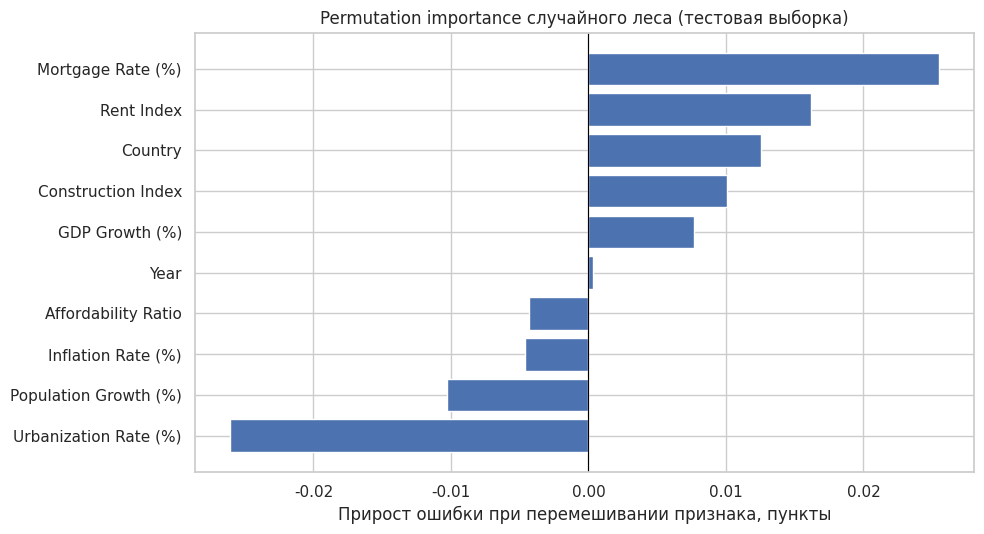

In [18]:
rf_best = rf_search.best_estimator_
rf_best.fit(X_train, y_train)

perm = permutation_importance(rf_best, X_test, y_test, n_repeats=30,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_series = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)

builtin = pd.Series(
    rf_best.named_steps["model"].feature_importances_,
    index=feature_names,
).groupby(lambda n: n if n in FEATURES else "Country").sum().sort_values(ascending=False)

display(pd.DataFrame({
    "Permutation importance": perm_series.round(4),
    "Встроенная важность": builtin.reindex(perm_series.index).round(4),
}))
pd.DataFrame({
    "Permutation importance": perm_series.round(4),
    "Встроенная важность": builtin.reindex(perm_series.index).round(4),
}).to_csv(DATA_DIR / "feature_importance.csv")
print("Сумма встроенных важностей по признакам:", round(builtin.sum(), 4))

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(perm_series.index[::-1], perm_series.values[::-1], color="#4C72B0")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Permutation importance случайного леса (тестовая выборка)")
ax.set_xlabel("Прирост ошибки при перемешивании признака, пункты")
plt.tight_layout()
save_fig(fig, "fig09_importance.png")
plt.show()


## 8. Контрольные эксперименты: проверка гипотезы об отсутствии сигнала

Результаты раздела 6 требуют объяснения: почему модели не превосходят
константный прогноз? Возможны два объяснения — либо выбранные методы
не подходят к данным, либо в данных действительно нет связи между
признаками и целевой переменной. Чтобы различить эти варианты, выполнены
три контрольных эксперимента.

**Эксперимент 1 — классификация.** Предсказывается бинарный признак
«индекс цен на жильё выше или ниже медианы по своей стране» (отклонение
рынка от собственного среднего уровня). Использованы логистическая
регрессия и случайный лес-классификатор.

**Эксперимент 2 — перемешанная целевая переменная (sanity check).**
Целевая переменная случайно перемешивается, после чего модели обучаются
заново. Если качество на перемешанных данных statistically не отличается
от качества на исходных данных, значит модели извлекают из признаков
не больше информации, чем из случайного шума.


In [19]:
country_median = df.groupby("Country")[TARGET].transform("median")
y_cls = (df[TARGET] > country_median).astype(int)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X, y_cls, test_size=0.2, random_state=RANDOM_STATE, stratify=y_cls
)

cls_models = {
    "Логистическая регрессия": make_pipeline(LogisticRegression(max_iter=5000)),
    "Случайный лес (классификатор)": make_pipeline(
        RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1)
    ),
}

cls_rows = []
for name, model in cls_models.items():
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_test)
    cv_acc = cross_validate(model, X, y_cls, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                            scoring="accuracy", n_jobs=-1)["test_score"]
    cls_rows.append({
        "Модель": name,
        "Accuracy (тест)": accuracy_score(yc_test, pred),
        "F1 (тест)": f1_score(yc_test, pred),
        "Accuracy (CV)": cv_acc.mean(),
        "Accuracy std (CV)": cv_acc.std(),
    })

cls_table = pd.DataFrame(cls_rows).set_index("Модель").round(3)
display(cls_table)
cls_table.to_csv(DATA_DIR / "classification_metrics.csv")
print("Доля мажоритарного класса:", round(max(y_cls.mean(), 1 - y_cls.mean()), 3))


,Accuracy (тест),F1 (тест),Accuracy (CV),Accuracy std (CV)
Модель,,,,
Логистическая регрессия,0.35,0.350,0.425,0.055
Случайный лес (классификатор),0.40,0.429,0.525,0.016


Доля мажоритарного класса: 0.5


In [20]:
# Эксперимент 2: перемешанная целевая переменная
rng = np.random.default_rng(RANDOM_STATE)
y_shuffled = pd.Series(rng.permutation(y.values), index=y.index, name=TARGET)

sanity_rows = []
for name, model in [
    ("Линейная регрессия", make_pipeline(LinearRegression())),
    ("Случайный лес", make_pipeline(RandomForestRegressor(
        n_estimators=400, min_samples_leaf=2, max_features="sqrt",
        random_state=RANDOM_STATE, n_jobs=-1))),
]:
    real = cross_validate(model, X, y, cv=CV, scoring=SCORING, n_jobs=-1)
    fake = cross_validate(model, X, y_shuffled, cv=CV, scoring=SCORING, n_jobs=-1)
    sanity_rows.append({
        "Модель": name,
        "R² исходная цель": real["test_r2"].mean(),
        "R² перемешанная цель": fake["test_r2"].mean(),
        "MAE исходная цель": -real["test_mae"].mean(),
        "MAE перемешанная цель": -fake["test_mae"].mean(),
    })

sanity_table = pd.DataFrame(sanity_rows).set_index("Модель").round(3)
display(sanity_table)
sanity_table.to_csv(DATA_DIR / "sanity_check.csv")
print("Вывод: качество на перемешанной цели не лучше, чем на исходной —")
print("признаки не содержат информации о целевой переменной.")


,R² исходная цель,R² перемешанная цель,MAE исходная цель,MAE перемешанная цель
Модель,,,,
Линейная регрессия,-0.207,-0.232,26.643,26.218
Случайный лес,-0.060,-0.104,25.291,25.663


Вывод: качество на перемешанной цели не лучше, чем на исходной —
признаки не содержат информации о целевой переменной.


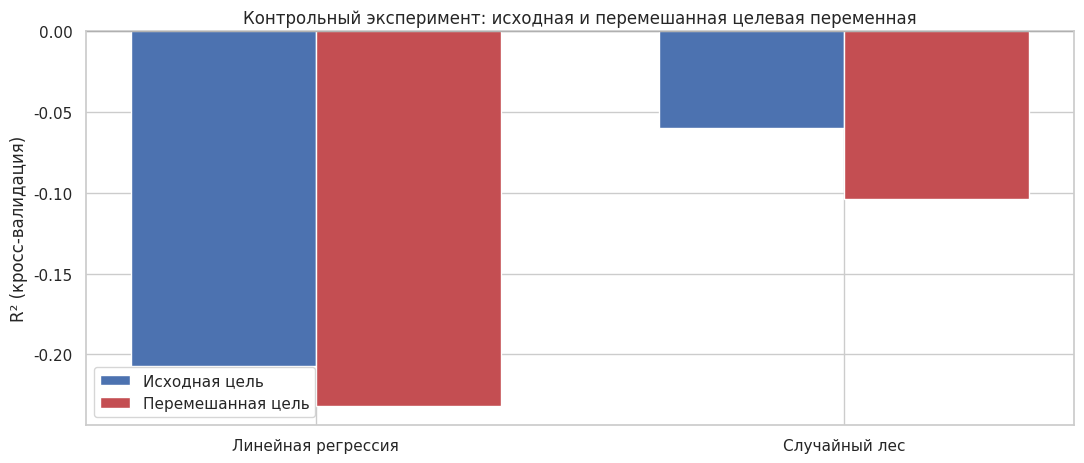

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.8))
plot_s = sanity_table[["R² исходная цель", "R² перемешанная цель"]]
x_pos = np.arange(len(plot_s))
width = 0.35
ax.bar(x_pos - width / 2, plot_s["R² исходная цель"], width, label="Исходная цель", color="#4C72B0")
ax.bar(x_pos + width / 2, plot_s["R² перемешанная цель"], width, label="Перемешанная цель", color="#C44E52")
ax.set_xticks(x_pos)
ax.set_xticklabels(plot_s.index)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("R² (кросс-валидация)")
ax.set_title("Контрольный эксперимент: исходная и перемешанная целевая переменная")
ax.legend()
plt.tight_layout()
save_fig(fig, "fig10_sanity.png")
plt.show()


## 9. Выводы


In [22]:
best_reg = final_table.drop(index=[i for i in final_table.index if i.startswith("Baseline")])
best_row = best_reg["MAE (тест)"].idxmin()

print("=" * 78)
print("ИТОГОВОЕ СРАВНЕНИЕ")
print("=" * 78)
print(final_table.to_string())
print()
print(f"Лучшая модель по MAE на тесте: {best_row}")
print(f"R² лучшей модели: {final_table.loc[best_row, 'R² (тест)']:.3f}")
print(f"R² baseline (среднее): {final_table.loc['Baseline (среднее)', 'R² (тест)']:.3f}")
print(f"MAE baseline (среднее): {final_table.loc['Baseline (среднее)', 'MAE (тест)']:.3f}")
print()
print("Контрольная классификация:")
print(cls_table.to_string())
print()
print("Контроль на перемешанной цели:")
print(sanity_table.to_string())


ИТОГОВОЕ СРАВНЕНИЕ
                              R² (тест)  MAE (тест)  RMSE (тест)  MAPE, % (тест)  R² (CV)  R² std (CV)  MAE (CV)  RMSE (CV)
Модель                                                                                                                     
Baseline (среднее)               -0.005      27.551       30.434          23.250   -0.008        0.011    25.117     28.689
Baseline (медиана)               -0.002      27.510       30.387          23.076   -0.023        0.041    25.346     28.892
Baseline (среднее по стране)     -0.038      26.788       30.932          22.913   -0.124          NaN    26.068     30.411
Линейная регрессия               -0.030      26.387       30.806          22.663   -0.207        0.163    26.643     31.297
Гребневая регрессия (Ridge)      -0.005      27.361       30.433          23.132   -0.009        0.035    25.182     28.705
Случайный лес                    -0.006      26.843       30.443          22.711   -0.048        0.073    25.392 